Saving library_management_200.csv to library_management_200 (1).csv
First Five Records:
   Book_ID                Book_Name        Author      Category  Member_ID  \
0    10001       Python Programming    John Smith   Programming       1001   
1    10002      Database Management     David Lee      Database       1002   
2    10003  Artificial Intelligence    Sam Wilson            AI       1003   
3    10004         Java Programming    Mike Brown   Programming       1004   
4    10005      Data Science Basics  Alice Thomas  Data Science       1005   

   Issue_Date Return_Date  Fine    Status  
0  2026-01-01  2026-01-11     0  Returned  
1  2026-02-02  2026-02-12    20   Overdue  
2  2026-03-03         NaN     0    Issued  
3  2026-04-04  2026-04-14     0  Returned  
4  2026-05-05  2026-05-15     0  Returned  

Dataset Shape: (200, 9)

Column Names:
Index(['Book_ID', 'Book_Name', 'Author', 'Category', 'Member_ID', 'Issue_Date',
       'Return_Date', 'Fine', 'Status'],
      dtype='objec

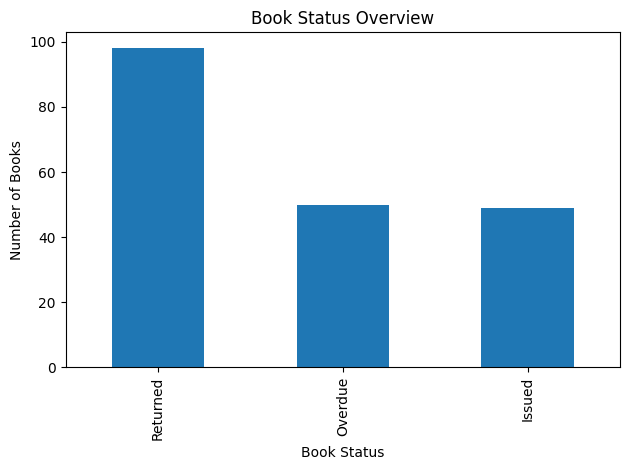

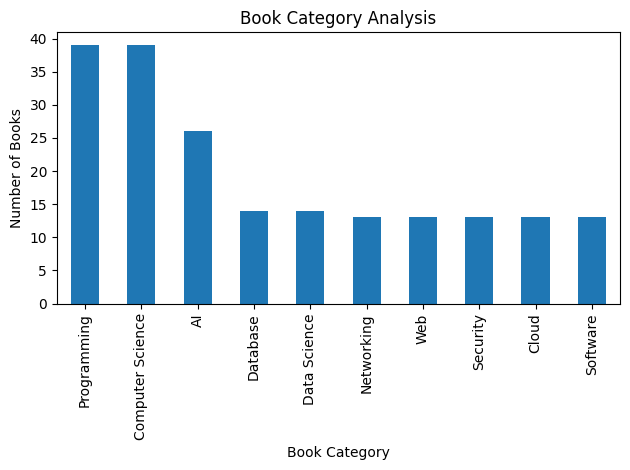


Prediction Results:
Actual Values: [0 0 0 0 1 1 0 0 0 0 1 0 0 1 0 0 0 1 0 1 1 0 1 1 0 0 1 0 0 1 0 1 0 0 0 0 1
 0 0 1]
Predicted Values: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0]

Model Evaluation:
Accuracy: 65.0 %
Precision: 0.0
Recall: 0.0
F1-score: 0.0


In [3]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from google.colab import files
uploaded = files.upload()

# Step 1: Load the dataset
df = pd.read_csv("library_management_200.csv")

print("First Five Records:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)

# Step 2: Check missing values and duplicates
print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

# Step 3: Clean the dataset
df = df.drop_duplicates()
df["Return_Date"] = df["Return_Date"].fillna("Not Returned")

print("\nAfter Cleaning")
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

# Step 4: Visualize book status
df["Status"].value_counts().plot(kind="bar")
plt.title("Book Status Overview")
plt.xlabel("Book Status")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

# Step 5: Visualize book categories
df["Category"].value_counts().plot(kind="bar")
plt.title("Book Category Analysis")
plt.xlabel("Book Category")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

# Step 6: Prepare data for prediction
X = df[["Author", "Category"]]
y = (df["Status"] == "Overdue").astype(int)

X = pd.get_dummies(X)

# Step 7: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 8: Train the Logistic Regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Step 9: Make predictions
y_pred = model.predict(X_test)

print("\nPrediction Results:")
print("Actual Values:", y_test.values)
print("Predicted Values:", y_pred)

# Step 10: Evaluate the model
print("\nModel Evaluation:")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 2))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 2))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 2))
